# Stacked Bar Chart (Expansion vs Contraction Revenue)

## Исходные данные для построения

- pandas.core.series.Series

Как сохранить: `expansion_summary.to_csv('expansion_summary.csv')`

In [2]:
expansion_summary = pd.read_csv('expansion_summary.csv', index_col=0).squeeze()
expansion_summary

Revenue_Type
Contraction   -2034792.0
Expansion      3329751.0
Name: Revenue_Change, dtype: float64

## Код для построения

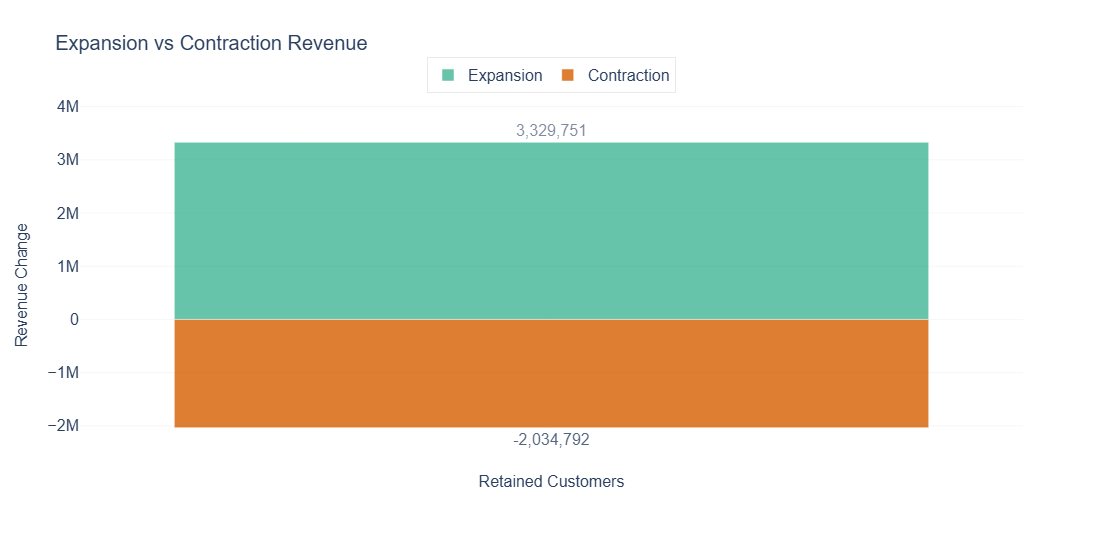

In [3]:
# =====================================================
# IMPORTS
# =====================================================

import pandas as pd
import plotly.graph_objects as go

# =====================================================
# The meaning of colors
# =====================================================

POSITIVE = '#009E73'
NEGATIVE = '#D55E00'

# =====================================================
# LOAD DATA
# =====================================================

expansion_summary = pd.read_csv('expansion_summary.csv', index_col=0).squeeze()

# =====================================================
# PREPARE VALUES
# =====================================================

expansion_total = expansion_summary.get('Expansion', 0)
contraction_total = abs(expansion_summary.get('Contraction', 0))

# =====================================================
# STACKED BAR CHART
# =====================================================

# Создаем пустую фигуру (Figure) — контейнер для графиков
# go.Figure() — создает объект, в который будем добавлять слои (traces)
fig = go.Figure()

# ============================================
# ДОБАВЛЯЕМ ПЕРВЫЙ СЛОЙ (Expansion — положительная часть)
# ============================================
# add_trace() — добавляет новый слой (trace) на фигуру
# Expansion
fig.add_trace(
    go.Bar( # go.Bar() — создает столбчатую диаграмму (bar chart)
        name='Expansion', # name — название слоя (отображается в легенде)
        x=['Retained Customers'], # x — значения по оси X (категории) ['Retained Customers'] — одна категория (один столбец
        y=[expansion_total], # y — значения по оси Y (высота столбца) [expansion_total] — одно значение (высота положительной части)
        opacity=0.6, # opacity — прозрачность заливки (0.6 = 60% непрозрачности)
        marker_color=POSITIVE, # marker_color — цвет заливки столбца
        # text — текст, который будет отображаться на/над столбцом 
        text=[f"{expansion_total:,.0f}"],  # ← форматирование с запятыми f"{expansion_total:,.0f}" — форматирование с разделителями тысяч
        textposition='outside' # textposition — положение текста относительно столбца 'outside' — текст снаружи (над столбцом)
    )
)
# ============================================
# ДОБАВЛЯЕМ ВТОРОЙ СЛОЙ (Contraction — отрицательная часть)
# ============================================
# Contraction
fig.add_trace(
    go.Bar(
        name='Contraction', # name — название слоя (отображается в легенде)
        x=['Retained Customers'], # x — та же категория, что и у Expansion (для группировки)
        y=[-contraction_total], # y — отрицательное значение (столбец уходит вниз) -contraction_total — делаем отрицательным для отображения вниз
        opacity=0.8, # opacity — прозрачность заливки (0.8 = 80% непрозрачности)
        marker_color=NEGATIVE, # marker_color — цвет заливки столбца
        # text — текст над столбцом с минусом
        text=[f"-{contraction_total:,.0f}"],  # ← форматирование с запятыми f"-{contraction_total:,.0f}" — форматирование с разделителями тысяч
        textposition='outside' # textposition — текст снаружи (над столбцом, т.е. под ним)
    )
)

# =====================================================
# LAYOUT
# =====================================================
# НАСТРОЙКА МАКЕТА (LAYOUT) ГРАФИКА
fig.update_layout( # update_layout() — применяет общие настройки к фигуре
    title={  # title — настройки заголовка
        'text': 'Expansion vs Contraction Revenue', # текст заголовка
        'font': {'size': 20} # размер шрифта заголовка
    },
    # barmode — режим отображения столбцов
    barmode='relative',  # 'relative' — столбцы строятся относительно друг друга (положительные вверх, отрицательные вниз от нуля)
    
    yaxis=dict( # yaxis — настройки оси Y (вертикальной)
        title={ # title — настройки подписи оси Y
            'text': 'Revenue Change', # текст подписи оси
            'font': {'size': 16} # размер шрифта подписи
        },
        # tickfont — настройки шрифта чисел на оси 
        tickfont=dict(size=16), # размер чисел на оси Y
        # tickformat — формат отображения чисел на оси (закомментировано)
        #tickformat=',.0f',          # ← формат для оси Y с запятыми. ',.0f' — разделители тысяч, без десятичных знаков. tickformat=',.0f',
        gridcolor='#EDEDED', # gridcolor — цвет линий сетки
        gridwidth=0.5, # gridwidth — толщина линий сетки
        showgrid=True, # showgrid — показывать ли сетку по оси Y. # да, показывать
        zeroline=False  # zeroline — показывать ли линию на нуле. # нет, не показывать
    ),
    
    xaxis=dict( # xaxis — настройки оси X (горизонтальной)
        title={ # title — подпись оси X (закомментирована, т.е. отсутствует)
            #'text': 'Customer Segment',
            'font': {'size': 16} # размер шрифта
        },
        tickfont=dict(size=16) # размер чисел на оси X
    ),
    
    legend=dict( # legend — настройки легенды
        orientation='h', # orientation — ориентация легенды: 'h' = горизонтальная, 'v' = вертикальная
        # yanchor — точка привязки по вертикали 
        yanchor='bottom', # привязка снизу
        # y — вертикальная позиция легенды (относительно графика)
        y=1.02, # чуть выше графика (1.0 = верхняя граница)
        # xanchor — точка привязки по горизонтали
        xanchor='center', # привязка по центру
        # x — горизонтальная позиция легенды
        x=0.5, # по центру
        # font — настройки шрифта в легенде
        font=dict(size=16), # размер шрифта
        bgcolor='rgba(255,255,255,0.8)', # bgcolor — цвет фона легенды
        bordercolor='lightgray', # bordercolor — цвет рамки легенды
        borderwidth=0.5 # borderwidth — толщина рамки легенды 0.5 пикселя
    ),
    # template — готовый стиль оформления
    template='plotly_white',  # белый фон, минималистичный стиль
    height=550, # height — высота фигуры в пикселях
    width=1000, # width — ширина фигуры в пикселях
    # font — базовые настройки шрифта для всей фигуры
    font={'family': 'Arial', 'size': 14}
)

# =====================================================
# ДОПОЛНИТЕЛЬНАЯ НАСТРОЙКА ТЕКСТА
# =====================================================

fig.update_traces( # update_traces() — применяет настройки ко всем слоям (traces)
    textfont=dict(size=16), # textfont — настройки шрифта для текста на столбцах # размер шрифта значений на столбцах
    textposition='outside' # textposition — положение текста (уже задано в каждом trace, но можно переопределить) # текст снаружи столбцов
)

fig.show() # show() — отображает график в браузере / Jupyter Notebook